In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd /content/drive/My Drive/ColabNotebooks/IS110_BPerformance_Lorenzana/workbook_Lorenzana

/content/drive/My Drive/ColabNotebooks/IS110_BPerformance_Lorenzana/workbook_Lorenzana


In [3]:
from google.colab import drive
drive.mount('/content/drive')

!ls "/content/drive/My Drive/Colab Notebooks"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
'Copy of Pandas for Data Manipulation and Analysis-1.1 .ipynb'	 ICT110-AppDev


In [ ]:
import os
os.makedirs("/content/drive/My Drive/Colab Notebooks/ICT110-AppDev/ColabNotes", exist_ok=True)
%cd "/content/drive/My Drive/Colab Notebooks/ICT110-AppDev/ColabNotes"

/content/drive/My Drive/Colab Notebooks/ICT110-AppDev/ColabNotes


In [ ]:
%cd /content/drive/My Drive/Colab Notebooks/ICT110-AppDev/ColabNotes

/content/drive/My Drive/Colab Notebooks/ICT110-AppDev/ColabNotes


In [ ]:
!pwd

/content


**MEA JEAN S. LORENZANA**

**EXERCISE 2.1**

Load to a dataframe the file `GDP(PPP)_LifeExpectancy.xlsx` in the folder `Datasets`.
- Don't load the column Code which contains the full name of the country
- Use the following column names: 'Country', 'Life_Exp', 'GDP', 'Population', 'Inc_Class'
- Encode invalid values to `np.nan`

In [ ]:
import pandas as pd
import numpy as np

raw = pd.read_excel(
    'GDP(PPP)_LifeExpectancy.xlsx',
    usecols=[0, 3, 17],      # Country Name, Series Code, 2023 (skips Country Code)
    names=['Country', 'Series', 'Value'],
    header=0,
    na_values=['..']
)
raw = raw[raw['Series'].isin(['NY.GDP.PCAP.PP.CD', 'SP.DYN.LE00.IN'])]
raw['Value'] = pd.to_numeric(raw['Value'], errors='coerce')

df_gdp = (raw.pivot(index='Country', columns='Series', values='Value')
             .rename(columns={'SP.DYN.LE00.IN': 'Life_Exp', 'NY.GDP.PCAP.PP.CD': 'GDP'})
             .reset_index())
df_gdp.columns.name = None
df_gdp['Population'] = np.nan   # the file GDP(PPP)_LifeExpectancy.xlsx contains no Population
df_gdp['Inc_Class'] = np.nan    # the file GDP(PPP)_LifeExpectancy.xlsx contains no Inc_Class data.
df_gdp = df_gdp[['Country', 'Life_Exp', 'GDP', 'Population', 'Inc_Class']]

df_gdp.head()

,Country,Life_Exp,GDP,Population,Inc_Class
0,Afghanistan,66.035,2201.722907,NaN,NaN
1,Albania,79.602,21259.797781,NaN,NaN
2,Algeria,76.261,16824.487903,NaN,NaN
3,American Samoa,72.852,NaN,NaN,NaN
4,Andorra,84.041,71730.668682,NaN,NaN


**EXERCISE 3.1**

The BitCoin Year-on-Year price data in CSV format could be found in this link: https://api.blockchain.info/charts/market-price?format=csv.
1. Download a copy of the CSV file and observe its characteristics.
2. Load the file directly from the url/website and assign it to a DataFrame called `df_bitcoin`
3. Plot the data

In [ ]:
import pandas as pd

url = 'https://api.blockchain.info/charts/market-price?format=csv'

df_bitcoin = pd.read_csv(url, header=None, names=['Date', 'Price'],
                         parse_dates=['Date'], index_col='Date')

df_bitcoin.head()

,Price
Date,
2025-10-27,114531.59
2025-10-28,114121.46
2025-10-29,112923.91
2025-10-30,110068.52
2025-10-31,108303.21


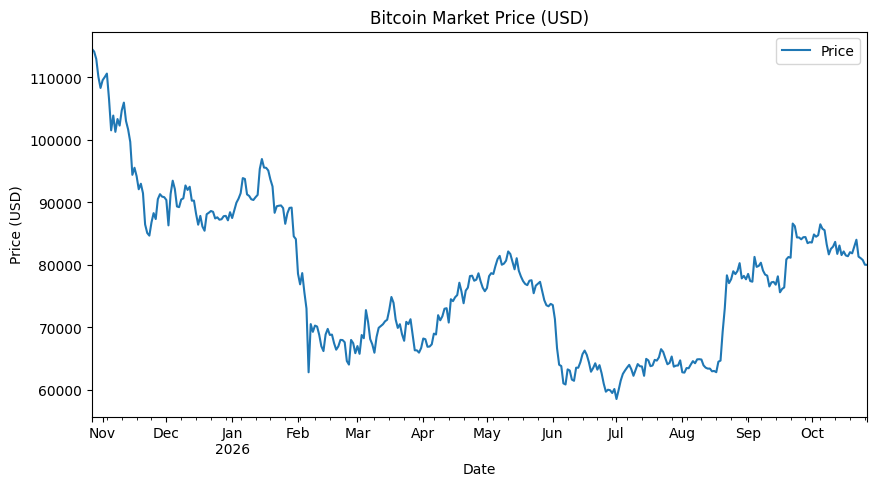

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

df_bitcoin.plot(figsize=(10, 5), title='Bitcoin Market Price (USD)')
plt.ylabel('Price (USD)')
plt.show()

In [ ]:
print(df_bitcoin.shape)
df_bitcoin.describe()

(366, 1)


,Price
count,366.000000
mean,77645.425027
std,11927.977288
min,58534.280000
25%,66938.032500
50%,77294.580000
75%,86396.280000
max,114531.590000


   **Observations:** The CSV has no header row and two columns (date and price in USD), with one row per day for a year (366 rows) and no missing values.

**EXERCISE 4.1**

Answer the following questions regarding the `df_gdp` you created in Exercise 2.1:

1. What are the dimensions of the DataFrame?

In [ ]:
df_gdp.shape

(217, 5)

2. How many valid GDP values are there?

In [ ]:
df_gdp['GDP'].count()

np.int64(197)

 3. What is the average life expectancy for all countries?

In [ ]:
df_gdp['Life_Exp'].mean()

np.float64(73.80012419916825)

 4. Sort the dataframe by Country and assign it to a new DataFrame

In [ ]:
df_sorted = df_gdp.sort_values(by='Country')
df_sorted.head()

,Country,Life_Exp,GDP,Population,Inc_Class
0,Afghanistan,66.035,2201.722907,NaN,NaN
1,Albania,79.602,21259.797781,NaN,NaN
2,Algeria,76.261,16824.487903,NaN,NaN
3,American Samoa,72.852,NaN,NaN,NaN
4,Andorra,84.041,71730.668682,NaN,NaN


5. What are the top 5 countries with the highest GDP?

In [ ]:
df_gdp.sort_values(by='GDP', ascending=False).head(5)

,Country,Life_Exp,GDP,Population,Inc_Class
171,Singapore,82.895122,143786.136293,NaN,NaN
116,Luxembourg,83.358537,142424.729887,NaN,NaN
159,Qatar,82.368000,128918.549293,NaN,NaN
93,Ireland,82.860976,124900.938635,NaN,NaN
117,"Macao SAR, China",83.180488,116491.377162,NaN,NaN


6. What are the top 5 countries with smallest population?

In [ ]:
if df_gdp['Population'].count() > 0:
    display(df_gdp.sort_values(by='Population').head(5))
else:
    print("Cannot be answered: this file has no population data (Population is all NaN).")

Cannot be answered: this file has no population data (Population is all NaN).
